  [binary] confound=0.2 done (5s)
  [binary] confound=0.4 done (10s)
  [binary] confound=0.6 done (15s)
  [binary] confound=0.8 done (19s)
  [binary] effect=0.8 done (24s)
  [binary] effect=1.5 done (29s)
  [binary] effect=2.2 done (33s)
  [binary] effect=3.0 done (38s)
  [continuous] confound=0.2 done (42s)
  [continuous] confound=0.4 done (46s)
  [continuous] confound=0.6 done (50s)
  [continuous] confound=0.8 done (54s)
  [continuous] effect=0.8 done (58s)
  [continuous] effect=1.5 done (62s)
  [continuous] effect=2.2 done (66s)
  [continuous] effect=3.0 done (70s)

================ SUMMARY ================

--- BINARY latent ---
interaction AUC      : {'GWAS': [0.94, 0.95, 0.91, 0.93], 'IBI-DT': [0.73, 0.68, 0.64, 0.59], 'Pathway': [0.94, 0.95, 0.93, 0.93]}
interaction Type I   : {'GWAS': [0.0, 0.03, 0.2, 0.09], 'IBI-DT': [0.03, 0.08, 0.12, 0.08], 'Pathway': [0.03, 0.08, 0.11, 0.09]}
DRIVER Type I        : {'GWAS': [0.11, 0.56, 0.81, 1.0], 'IBI-DT': [0.14, 0.39, 0.41, 0.48], 'Pathw

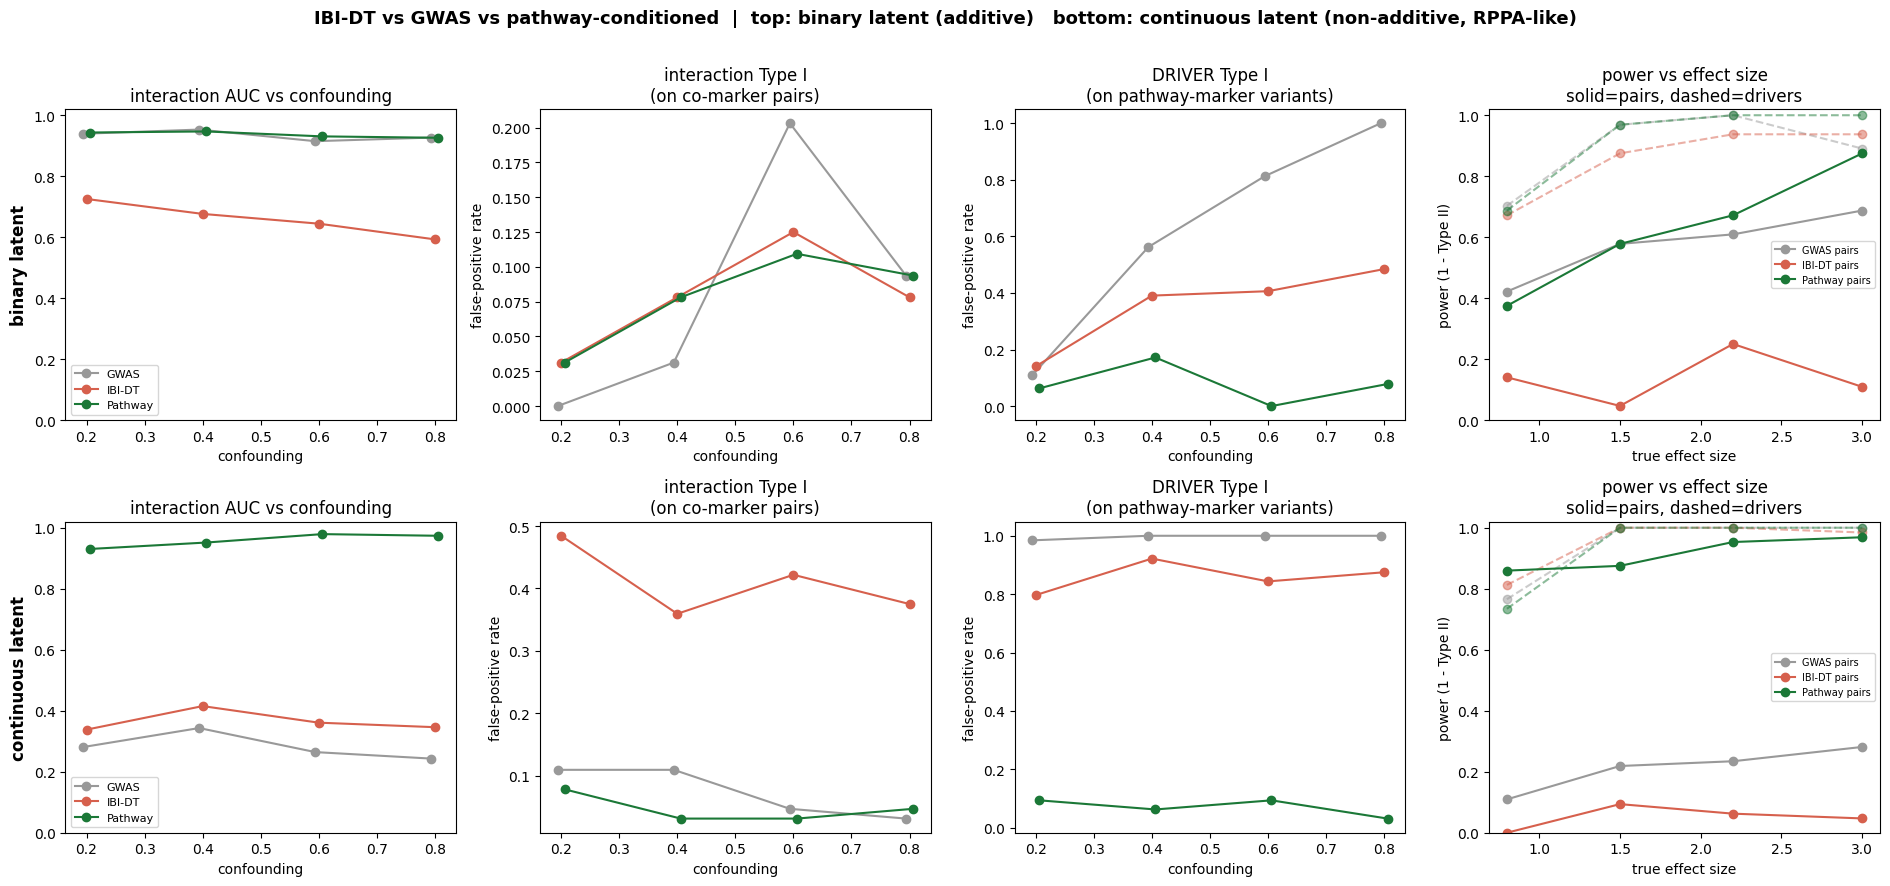

In [1]:
"""
Error-rate study v2: drivers AND interactions, binary vs continuous latent
==========================================================================
Same generator family as before (hidden pathway -> marker genes -> outcome T),
now with two additions you asked for:

  1) DRIVER Type I / Type II, not just interactions. Single-variant detection
     is the alpha side of IBI-DT, and it is exactly where additive confounding
     inflates marginal tests -- so it is where conditioning on the pathway helps
     most. We report driver false-positive rate on null variants and power.

  2) A CONTINUOUS-LATENT variant. Biologically: a pathway is not an on/off
     switch but an ACTIVITY LEVEL, and its read-outs are continuous protein /
     expression measurements (think RPPA). Mathematically this is the regime
     where the shared latent leaks a spurious PRODUCT term into the outcome
     (phantom epistasis for interactions), so conditioning on the inferred
     latent should pull clearly ahead of a plain product-term (GWAS) test.

       binary latent     : Z in {0,1}, markers Bernoulli(theta_z)   -> additive
       continuous latent : Z ~ N(0,1), markers G = lambda*Z + noise -> NOT additive

Three method arms throughout:
   GWAS     : one-at-a-time. Marginal logistic per variant (drivers);
              logistic with a product term per pair (interactions).
   IBI-DT   : faithful tree ensemble -> alpha (drivers), beta (interactions),
              with the random-node null as the significance threshold.
   Pathway  : infer the latent pathway state from its markers (Gibbs latent
              class for binary; Gaussian factor model for continuous), then
              test each variant / pair AFTER conditioning on it; calibrated.

Method lineage (NOT invented here): latent-confounder adjustment = SVA / PEER /
RUV; Bayesian null/main/interaction partition = BEAM; the failure mode = phantom
epistasis. Contribution here is the diagnosis + pathway-anchored assembly.

Self-contained: numpy / scipy / sklearn / matplotlib.
"""

import numpy as np
from scipy.special import gammaln, expit, logsumexp
from sklearn.metrics import roc_auc_score
import matplotlib.pyplot as plt
import time

# ============================================================================
# shared marginal-likelihood / evidence pieces
# ============================================================================
def lgm_edge(T, Vmat):
    T = T.astype(np.int64); Vmat = Vmat.astype(np.int64)
    t1, t0 = T, 1 - T
    V1D1 = t1 @ Vmat; V1D0 = t0 @ Vmat
    V0D1 = t1 @ (1 - Vmat); V0D0 = t0 @ (1 - Vmat)
    lg = np.zeros(Vmat.shape[1])
    for a, b in [(V0D0, V0D1), (V1D0, V1D1)]:
        lg += gammaln(2.0) - gammaln(2.0 + a + b) + gammaln(1.0 + a) + gammaln(1.0 + b)
    return lg

def lgm_noparent(T):
    N = len(T); N1 = int(T.sum())
    return gammaln(2.0) - gammaln(2.0 + N) + gammaln(1.0 + N - N1) + gammaln(1.0 + N1)

def logistic_logevidence(X, y, tau=4.0, iters=40):
    d = X.shape[1]; b = np.zeros(d); P = np.eye(d) / tau**2
    for _ in range(iters):
        mu = expit(X @ b); W = mu * (1 - mu) + 1e-9
        H = X.T @ (X * W[:, None]) + P
        step = np.linalg.solve(H, X.T @ (y - mu) - P @ b); b += step
        if np.max(np.abs(step)) < 1e-7:
            break
    eta = X @ b; mu = expit(eta); W = mu * (1 - mu) + 1e-9
    ll = np.sum(y * eta - np.logaddexp(0.0, eta))
    _, logdetH = np.linalg.slogdet(X.T @ (X * W[:, None]) + P)
    return ll - 0.5 * (b @ b) / tau**2 - 0.5 * logdetH

def logistic_wald_p(X, y, idx, iters=40):
    from math import erfc, sqrt
    d = X.shape[1]; b = np.zeros(d)
    for _ in range(iters):
        mu = expit(X @ b); W = mu * (1 - mu) + 1e-9
        H = X.T @ (X * W[:, None]) + 1e-6 * np.eye(d)
        step = np.linalg.solve(H, X.T @ (y - mu)); b += step
        if np.max(np.abs(step)) < 1e-7:
            break
    mu = expit(X @ b); W = mu * (1 - mu) + 1e-9
    cov = np.linalg.inv(X.T @ (X * W[:, None]) + 1e-9 * np.eye(d))
    z = b[idx] / np.sqrt(max(cov[idx, idx], 1e-12))
    return erfc(abs(z) / sqrt(2))

# ============================================================================
# STEP 1 -- infer the latent, TWO versions
# ============================================================================
def infer_Z_binary(G_block, n_draws=12, iters=500, burn=200, seed=0):
    """Gibbs latent-class model for BINARY markers -> posterior draws of Z in {0,1}."""
    rng = np.random.default_rng(seed); n, m = G_block.shape
    Z = (rng.random(n) < 0.5).astype(int); draws = []; thin = max((iters - burn)//n_draws, 1)
    for it in range(iters):
        th = np.empty((m, 2))
        for z in (0, 1):
            on = G_block[Z == z].sum(0)
            th[:, z] = rng.beta(1 + on, 1 + ((Z == z).sum() - on))
        pi = rng.beta(1 + Z.sum(), 1 + (n - Z.sum()))
        if th[:, 1].sum() < th[:, 0].sum():
            th, pi, Z = th[:, ::-1], 1 - pi, 1 - Z
        lo = (np.log(pi/(1-pi)) + G_block @ np.log(th[:, 1]/th[:, 0])
              + (1 - G_block) @ np.log((1-th[:, 1])/(1-th[:, 0])))
        Z = (rng.random(n) < expit(lo)).astype(int)
        if it >= burn and (it-burn) % thin == 0 and len(draws) < n_draws:
            draws.append(Z.astype(float).copy())
    return np.array(draws)

def infer_Z_continuous(G_block, n_draws=12, iters=400, burn=150, seed=0):
    """One-factor Gaussian factor model for CONTINUOUS markers (RPPA-style):
       G_j = lambda_j * Z + noise.  Gibbs -> posterior draws of the factor Z (real)."""
    rng = np.random.default_rng(seed); n, m = G_block.shape
    G = (G_block - G_block.mean(0)) / (G_block.std(0) + 1e-9)
    lam = np.ones(m); psi = np.ones(m); Z = rng.standard_normal(n)
    draws = []; thin = max((iters - burn)//n_draws, 1)
    for it in range(iters):
        # Z_i | . ~ N(mu_i, v)   (posterior of the factor score)
        v = 1.0 / (1.0 + np.sum(lam**2 / psi))
        mu = v * (G @ (lam / psi))
        Z = mu + np.sqrt(v) * rng.standard_normal(n)
        # lambda_j | . ~ N(.,.)   (regress each marker on Z)
        zz = Z @ Z + 1e-6
        for j in range(m):
            mlam = (G[:, j] @ Z) / zz; vlam = psi[j] / zz
            lam[j] = mlam + np.sqrt(vlam) * rng.standard_normal()
        # psi_j | . ~ InvGamma  (residual variance)
        resid = G - np.outer(Z, lam)
        psi = (np.sum(resid**2, 0) + 1.0) / rng.chisquare(n + 2, size=m)
        if lam.sum() < 0:                    # fix sign (identifiability)
            lam, Z = -lam, -Z
        if it >= burn and (it-burn) % thin == 0 and len(draws) < n_draws:
            draws.append(Z.copy())
    return np.array(draws)                   # real-valued factor scores

# ============================================================================
# IBI-DT faithful tree + ensemble (binary inputs; for continuous markers we
# binarise at the median so IBI-DT still has something to split on, as a user
# would have to do in practice)
# ============================================================================
def grow(T, V, idx, cand, depth, max_depth, neglogq, min_n, used, path, paths):
    Tn = T[idx]
    if depth >= max_depth or len(idx) < min_n or Tn.min() == Tn.max():
        paths.append(list(path)); return
    usable = [c for c in cand if c not in used and V[idx, c].min() != V[idx, c].max()]
    if not usable:
        paths.append(list(path)); return
    gains = lgm_edge(Tn, V[np.ix_(idx, usable)]) - lgm_noparent(Tn)
    j = int(np.argmax(gains))
    if gains[j] <= neglogq:
        paths.append(list(path)); return
    s = usable[j]
    for branch in (0, 1):
        child = idx[V[idx, s] == branch]
        if len(child):
            grow(T, V, child, cand, depth+1, max_depth, neglogq, min_n,
                 used | {s}, path + [(s, branch)], paths)

def ibidt_alpha_beta(T, Vbin, N=30, max_depth=4, q=0.1, min_n=25, rng=None):
    rng = rng or np.random.default_rng(0)
    p = Vbin.shape[1]; cand = list(range(p)); neglogq = -np.log(q)
    alpha = np.zeros(p); beta = {}; i1, i0 = np.where(T == 1)[0], np.where(T == 0)[0]
    a_null = b_null = 0
    for _ in range(N):
        bs = np.concatenate([rng.choice(i0, len(i0), True), rng.choice(i1, len(i1), True)])
        paths = []
        grow(T[bs], Vbin[bs], np.arange(len(bs)), cand, 0, max_depth, neglogq, min_n, set(), [], paths)
        nodes = {v for pth in paths for v, _ in pth}
        for s in nodes: alpha[s] += 1
        seen = set()
        for pth in paths:
            vs = [v for v, _ in pth]
            for x in range(len(vs)):
                for y in range(x+1, len(vs)):
                    k = (min(vs[x], vs[y]), max(vs[x], vs[y]))
                    if k not in seen: beta[k] = beta.get(k, 0)+1; seen.add(k)
        ac, bc, bs2 = {}, {}, set()
        for pth in paths:
            rl = [int(rng.integers(p)) for _ in pth]
            for v in set(rl): ac[v] = ac.get(v, 0)+1
            for x in range(len(rl)):
                for y in range(x+1, len(rl)):
                    k = (min(rl[x], rl[y]), max(rl[x], rl[y]))
                    if k not in bs2: bc[k] = bc.get(k, 0)+1; bs2.add(k)
        a_null = max(a_null, max(ac.values()) if ac else 0)
        b_null = max(b_null, max(bc.values()) if bc else 0)
    return alpha, beta, a_null, b_null

# ============================================================================
# GENERATOR -- one function, switchable latent type
# ============================================================================
def make_data(effect_size=2.0, confound_strength=0.55, n=700, p_extra_nulls=12,
              n_pathways=2, per=5, n_drivers=4, n_inter=4, latent="binary", seed=0):
    rng = np.random.default_rng(seed)
    blocks, Zs = [], []
    for _ in range(n_pathways):
        if latent == "binary":
            Z = (rng.random(n) < 0.45).astype(float)
            theta1, theta0 = 0.5 + confound_strength/2, 0.5 - confound_strength/2
            B = np.zeros((n, per))
            for j in range(per):
                B[:, j] = (rng.random(n) < np.where(Z == 1, theta1, theta0)).astype(float)
        else:  # continuous: pathway ACTIVITY level; markers are noisy linear read-outs (RPPA-like)
            Z = rng.standard_normal(n)
            lam = 0.5 + confound_strength            # loading grows with confounding
            noise = np.sqrt(max(1.0 - 0.0, 0.3))
            B = lam * Z[:, None] + noise * rng.standard_normal((n, per))
        Zs.append(Z); blocks.append(B)

    D = (rng.random((n, n_drivers)) < 0.30).astype(float)        # true single-variant drivers
    E = (rng.random((n, 2*n_inter)) < 0.5).astype(float)         # true interaction genes
    NU = (rng.random((n, p_extra_nulls)) < 0.25).astype(float)   # nulls
    V = np.hstack(blocks + [D, E, NU])

    off = {}; c = 0
    for k in range(n_pathways): off[f"path{k}"] = c; c += per
    off["drv"] = c; c += n_drivers
    off["int"] = c; c += 2*n_inter
    off["null"] = c

    logit = -2.0
    for Z in Zs:
        logit = logit + (2.2 * Z if latent == "binary" else 1.6 * Z)   # pathway acts additively
    for d in range(n_drivers):
        logit = logit + effect_size * D[:, d]
    for q in range(n_inter):
        a, b = off["int"]+2*q, off["int"]+2*q+1
        logit = logit + effect_size * ((V[:, a] > 0.5) & (V[:, b] > 0.5)).astype(float)
    T = (rng.random(n) < expit(logit)).astype(int)

    # binarised copy of the SGA matrix for IBI-DT and as the 0/1 'genotype' for GWAS/pathway
    Vbin = (V > np.median(V, 0)).astype(float) if latent == "continuous" else V.copy()
    # for marker columns keep the binary draws when binary; for continuous, median-split
    marker_cols = list(range(n_pathways*per))

    true_drivers = set(range(off["drv"], off["drv"]+n_drivers))
    true_pairs = {(off["int"]+2*q, off["int"]+2*q+1) for q in range(n_inter)}
    marker_pick = [off["path0"]+0, off["path0"]+1] + \
                  ([off["path1"]+0, off["path1"]+1] if n_pathways > 1 else [])
    driver_cands = [(g, "pos") for g in range(off["drv"], off["drv"]+n_drivers)] + \
                   [(g, "null") for g in range(off["null"], off["null"]+min(6, p_extra_nulls))] + \
                   [(g, "phantom") for g in marker_pick]   # correlate with T via pathway only
    pair_cands = [(pr, "pos") for pr in true_pairs]
    for k in range(n_pathways):
        b0 = off[f"path{k}"]
        pair_cands += [((b0+0, b0+1), "phantom"), ((b0+2, b0+3), "phantom")]
    nb = off["null"]
    pair_cands += [((nb+0, nb+1), "null"), ((nb+2, nb+3), "null"), ((nb+4, nb+5), "null")]
    return dict(V=V, Vbin=Vbin, T=T, off=off, per=per, n_pathways=n_pathways, latent=latent,
                true_drivers=true_drivers, true_pairs=true_pairs,
                driver_cands=driver_cands, pair_cands=pair_cands, marker_cols=marker_cols)

# ============================================================================
# score one dataset with all three methods (drivers + pairs)
# ============================================================================
def score_dataset(dat, rng):
    V, Vbin, T = dat["V"], dat["Vbin"], dat["T"]; n = len(T); one = np.ones(n)
    alpha, beta, a_null, b_null = ibidt_alpha_beta(T, Vbin, rng=rng)
    infer = infer_Z_binary if dat["latent"] == "binary" else infer_Z_continuous
    Zd = [infer(dat["V"][:, dat["off"][f"path{k}"]:dat["off"][f"path{k}"]+dat["per"]],
                seed=int(rng.integers(1e9))) for k in range(dat["n_pathways"])]
    S = min(len(z) for z in Zd)
    Zlist = [np.column_stack([Zd[k][s] for k in range(dat["n_pathways"])]) for s in range(S)]

    # ---- drivers: returns rows (label, gwas, ibidt, pcond) + kind
    drv_rows, drv_kind = [], []
    for g, kind in dat["driver_cands"]:
        lab = int(kind == "pos"); Gg = Vbin[:, g].astype(float)
        gwas = -np.log(max(logistic_wald_p(np.column_stack([one, Gg]), T, 1), 1e-300))
        ibidt = alpha[g] - a_null
        ev0, ev1 = [], []
        for Z in Zlist:
            base = np.column_stack([one] + [Z[:, k] for k in range(Z.shape[1])])
            ev0.append(logistic_logevidence(base, T))
            ev1.append(logistic_logevidence(np.column_stack([base, Gg]), T))
        drv_rows.append((lab, gwas, ibidt, logsumexp(ev1)-logsumexp(ev0))); drv_kind.append(kind)

    # ---- pairs
    pair_rows, pair_kind = [], []
    for (a, b), kind in dat["pair_cands"]:
        lab = int(kind == "pos")
        Ga, Gb = Vbin[:, a].astype(float), Vbin[:, b].astype(float); inter = Ga*Gb
        gwas = -np.log(max(logistic_wald_p(np.column_stack([one, Ga, Gb, inter]), T, 3), 1e-300))
        ibidt = beta.get((min(a, b), max(a, b)), 0) - b_null
        ev_add, ev_int = [], []
        for Z in Zlist:
            base = np.column_stack([one] + [Z[:, k] for k in range(Z.shape[1])] + [Ga, Gb])
            ev_add.append(logistic_logevidence(base, T))
            ev_int.append(logistic_logevidence(np.column_stack([base, inter]), T))
        pair_rows.append((lab, gwas, ibidt, logsumexp(ev_int)-logsumexp(ev_add))); pair_kind.append(kind)
    return drv_rows, drv_kind, pair_rows, pair_kind

# ============================================================================
# run both latent types over the sweeps
# ============================================================================
def auc(L, S): return roc_auc_score(L, S) if len(set(L)) == 2 else np.nan
NATIVE = {"GWAS": -np.log(0.05), "IBI-DT": 0.5, "Pathway": np.log(3.0)}
methods = ["GWAS", "IBI-DT", "Pathway"]
R = 16
conf_grid = [0.2, 0.4, 0.6, 0.8]
t0 = time.time()

def run_latent(latent):
    # sweep confounding: interaction AUC, phantom Type I (pairs), driver Type I (null variants)
    pair_auc = {m: [] for m in methods}; pair_phantomI = {m: [] for m in methods}
    drv_typeI = {m: [] for m in methods}; drv_auc = {m: [] for m in methods}
    for cs in conf_grid:
        PL, Pk = {m: [] for m in methods}, []
        DL, Dk = {m: [] for m in methods}, []
        plab, dlab = [], []
        for r in range(R):
            dat = make_data(effect_size=2.0, confound_strength=cs, n=700, latent=latent,
                            seed=1000*r + int(cs*10))
            dr, dk, pr, pk = score_dataset(dat, np.random.default_rng(50000+r))
            dr = np.array(dr, float); pr = np.array(pr, float)
            dlab += list(dr[:, 0]); plab += list(pr[:, 0]); Dk += dk; Pk += pk
            for i, m in enumerate(methods):
                DL[m] += list(dr[:, i+1]); PL[m] += list(pr[:, i+1])
        plab, dlab = np.array(plab), np.array(dlab); Pk, Dk = np.array(Pk), np.array(Dk)
        for m in methods:
            sP, sD = np.array(PL[m]), np.array(DL[m])
            pair_auc[m].append(auc(plab, sP)); drv_auc[m].append(auc(dlab, sD))
            pair_phantomI[m].append(float(np.mean(sP[Pk == "phantom"] >= NATIVE[m])))
            drv_typeI[m].append(float(np.mean(sD[Dk == "phantom"] >= NATIVE[m])))
        print(f"  [{latent}] confound={cs} done ({time.time()-t0:.0f}s)")

    # sweep effect size: interaction power and driver power
    eff_grid = [0.8, 1.5, 2.2, 3.0]
    pair_pow = {m: [] for m in methods}; drv_pow = {m: [] for m in methods}
    for es in eff_grid:
        PL, DL, plab, dlab, Pk, Dk = {m: [] for m in methods}, {m: [] for m in methods}, [], [], [], []
        for r in range(R):
            dat = make_data(effect_size=es, confound_strength=0.55, n=700, latent=latent,
                            seed=2000*r + int(es*10))
            dr, dk, pr, pk = score_dataset(dat, np.random.default_rng(60000+r))
            dr = np.array(dr, float); pr = np.array(pr, float)
            dlab += list(dr[:, 0]); plab += list(pr[:, 0]); Dk += dk; Pk += pk
            for i, m in enumerate(methods):
                DL[m] += list(dr[:, i+1]); PL[m] += list(pr[:, i+1])
        plab, dlab = np.array(plab), np.array(dlab)
        for m in methods:
            sP, sD = np.array(PL[m]), np.array(DL[m])
            pair_pow[m].append(float(np.mean(sP[plab == 1] >= NATIVE[m])))
            drv_pow[m].append(float(np.mean(sD[dlab == 1] >= NATIVE[m])))
        print(f"  [{latent}] effect={es} done ({time.time()-t0:.0f}s)")
    return dict(conf=conf_grid, eff=eff_grid, pair_auc=pair_auc, pair_phantomI=pair_phantomI,
                drv_typeI=drv_typeI, drv_auc=drv_auc, pair_pow=pair_pow, drv_pow=drv_pow)

res = {"binary": run_latent("binary"), "continuous": run_latent("continuous")}

# ============================================================================
# figure : rows = {binary, continuous}, cols = 4 panels
# ============================================================================
col = {"GWAS": "#999999", "IBI-DT": "#d6604d", "Pathway": "#1b7837"}
jit = {"GWAS": -0.006, "IBI-DT": 0.0, "Pathway": 0.006}
fig, AX = plt.subplots(2, 4, figsize=(19, 9))
for row, latent in enumerate(["binary", "continuous"]):
    r = res[latent]; ax = AX[row]
    # 1: interaction AUC vs confounding
    for m in methods: ax[0].plot(np.array(r["conf"])+jit[m], r["pair_auc"][m], "o-", color=col[m], label=m)
    ax[0].set_ylim(0.0, 1.02); ax[0].set_ylabel(f"{latent} latent", fontsize=12, fontweight="bold")
    ax[0].set_title("interaction AUC vs confounding"); ax[0].set_xlabel("confounding"); ax[0].legend(fontsize=8)
    # 2: phantom Type I (pairs) vs confounding
    for m in methods: ax[1].plot(np.array(r["conf"])+jit[m], r["pair_phantomI"][m], "o-", color=col[m])
    ax[1].set_title("interaction Type I\n(on co-marker pairs)"); ax[1].set_xlabel("confounding")
    ax[1].set_ylabel("false-positive rate")
    # 3: DRIVER Type I vs confounding  (the newly added panel)
    for m in methods: ax[2].plot(np.array(r["conf"])+jit[m], r["drv_typeI"][m], "o-", color=col[m])
    ax[2].set_title("DRIVER Type I\n(on pathway-marker variants)"); ax[2].set_xlabel("confounding")
    ax[2].set_ylabel("false-positive rate")
    # 4: power vs effect size (pairs solid, drivers dashed)
    for m in methods:
        ax[3].plot(r["eff"], r["pair_pow"][m], "o-", color=col[m], label=f"{m} pairs")
        ax[3].plot(r["eff"], r["drv_pow"][m], "o--", color=col[m], alpha=.5)
    ax[3].set_ylim(0, 1.02); ax[3].set_title("power vs effect size\nsolid=pairs, dashed=drivers")
    ax[3].set_xlabel("true effect size"); ax[3].set_ylabel("power (1 - Type II)"); ax[3].legend(fontsize=7)
fig.suptitle("IBI-DT vs GWAS vs pathway-conditioned  |  top: binary latent (additive)   bottom: continuous latent (non-additive, RPPA-like)",
             fontsize=13, fontweight="bold")
fig.tight_layout(rect=[0, 0, 1, 0.97])
fig.savefig("error_rate_study_v2.png", dpi=135)

print("\n================ SUMMARY ================")
for latent in ["binary", "continuous"]:
    r = res[latent]
    print(f"\n--- {latent.upper()} latent ---")
    print("interaction AUC      :", {m: [round(x, 2) for x in r["pair_auc"][m]] for m in methods})
    print("interaction Type I   :", {m: [round(x, 2) for x in r["pair_phantomI"][m]] for m in methods})
    print("DRIVER Type I        :", {m: [round(x, 2) for x in r["drv_typeI"][m]] for m in methods})
    print("interaction power    :", {m: [round(x, 2) for x in r["pair_pow"][m]] for m in methods})
    print("driver power         :", {m: [round(x, 2) for x in r["drv_pow"][m]] for m in methods})
print("saved figure -> error_rate_study_v2.png")